In [1]:
import strahler
from importlib.metadata import version as package_version

package = package_version("strahler")
library = strahler.version()
if package != library:
    raise RuntimeError("Package/library version mismatch. Reinstall strahler in this kernel, "
                       "check STRAHLER_LIB, and restart the kernel before continuing.")
print("strahler package and library versions match")

from notebook_support import HERE, BACKENDS, metrics_table, table, won_vertices
from strahler.widgets import GameView, TreeView, Stepper
from IPython.display import display

strahler package and library versions match


# Compare backends, preprocessing, and iterative shaving

Compare the four backends, simple-dominion preprocessing (`+pre`), and
iterative shaving (`+iter`) where supported. Tree metrics describe the attractor
decomposition of each reported dominion in the remaining game (after preprocessing
and earlier shaving rounds). The won column also counts
preprocessing, earlier shaving rounds, and their attractors, whose certificates
are stored separately in result data. The same winners can have different tree
shapes.

In [2]:
game = strahler.Game.from_file(HERE / "otj22-fig1.gm")
results = {}
for backend in BACKENDS:
    for pre in (False, True):
        iterations = (False, True) if backend.startswith("lifting") else (False,)
        for iteration in iterations:
            name = backend + ("+pre" if pre else "") + ("+iter" if iteration else "")
            result = strahler.decompose(game, backend, initial_shave="all" if pre else None,
                                        iter_shave=iteration)
            assert result.complete and not result.unresolved
            assert won_vertices(result, 0) == set(game.vertices)
            results[name] = result
metrics_table(results)

backend,player,nodes,leaves,height,Strahler,dominion,won,complete,unresolved
zielonka,Even,5,3,3,2,10,10,True,0
zielonka,Odd,0,0,0,0,0,0,True,0
zielonka+pre,Even,5,3,3,2,10,10,True,0
zielonka+pre,Odd,0,0,0,0,0,0,True,0
zielonka-sym,Even,5,3,3,2,10,10,True,0
zielonka-sym,Odd,0,0,0,0,0,0,True,0
zielonka-sym+pre,Even,5,3,3,2,10,10,True,0
zielonka-sym+pre,Odd,0,0,0,0,0,0,True,0
lifting,Even,5,3,3,2,10,10,True,0
lifting,Odd,0,0,0,0,0,0,True,0


dominion: vertices covered by this player's attractor decomposition (its tree); won: every vertex this player wins, including vertices removed by preprocessing (+pre) or earlier shaving rounds (+iter); unresolved: vertices neither player's search certified.


`genstree` generates Strahler universal trees. The prefix trees use the same
JSON format as PR #31; the measured trees come from actual progress measures.
Inspect every round because iterative shaving removes earlier winners from
the next round's game. Empty player trees are explicit placeholders, not missing
results. Both views work without Graphviz or runtime browser downloads.

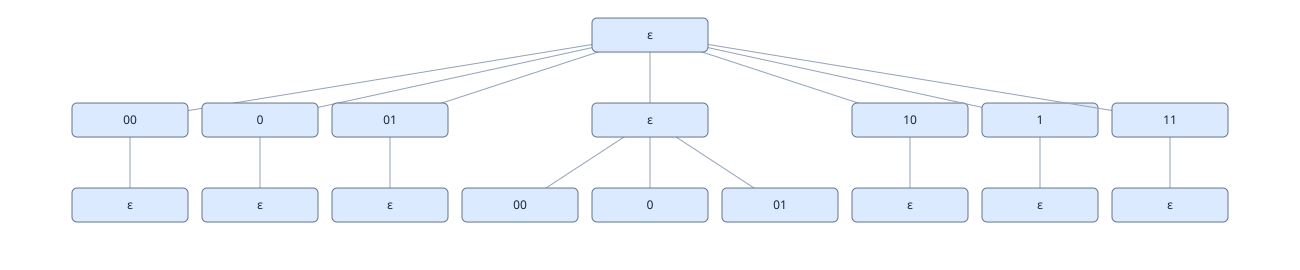

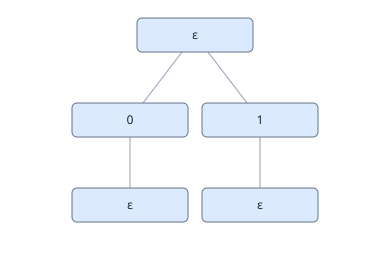

Round 1, Even; complete=False


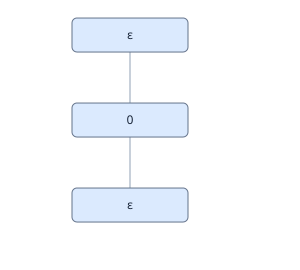

Round 1, Odd; complete=False


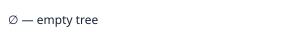

Round 2, Even; complete=True


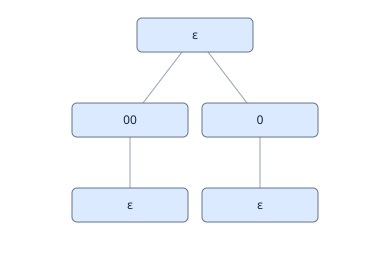

Round 2, Odd; complete=True


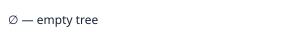

In [3]:
universal = strahler.genstree(k=2, h=3, t=1)
prefix = strahler.pms_tree("0,e|1,e|")
measures = strahler.progress_measures(game, algorithm="strahler", iter_shave=True)
display(TreeView(universal), TreeView(prefix))
for round_data in measures["rounds"]:
    for player, item in enumerate(round_data["trees"]):
        print(f"Round {round_data['round']}, {'Even' if player == 0 else 'Odd'}; "
              f"complete={round_data['complete']}")
        display(TreeView(item))